<div align="center">
  <img src="https://raw.githubusercontent.com/devicons/devicon/master/icons/python/python-original.svg" width="80"/>
</div>

<h1 align="center">Redes Neurais Convolucionais</h1>

<h3 align="center">Notebook 03: CNN em datasets reais</h3>

<p align="center"><b>PhD. Julles Mitoura</b></p>

<div align="center">
  <img src="https://img.shields.io/badge/Python-3776AB?style=for-the-badge&logo=python&logoColor=white"/>
  <img src="https://img.shields.io/badge/Jupyter-F37626?style=for-the-badge&logo=jupyter&logoColor=white"/>
  <img src="https://img.shields.io/badge/PyTorch-EE4C2C?style=for-the-badge&logo=pytorch&logoColor=white"/>
</div>

---

### Onde este notebook se encaixa na aula

| Notebook | Assunto | Ferramenta |
|---|---|---|
| 00 | Como uma rede aprende: erro, derivada e otimização | NumPy |
| 01 | Uma CNN construída do zero, operação por operação | NumPy |
| 02 | CNN com PyTorch em um dataset criado por nós | PyTorch |
| **03 (você está aqui)** | **CNN em datasets reais: MNIST e CIFAR-10** | **PyTorch** |

> **Pré-requisito:** o notebook `02_cnn_pytorch.ipynb`, onde o PyTorch e o vocabulário de tensores, lotes e otimizadores foram apresentados.

## O que vamos fazer neste notebook

Até aqui trabalhamos com dados que nós mesmos criamos: dois desenhos de 6×6 no notebook 01 e dígitos desenhados por código no notebook 02. Agora vamos usar **dois datasets reais e clássicos**, os mesmos que a comunidade de pesquisa usa há décadas para comparar modelos.

| Dataset | O que contém | Dificuldade |
|---|---|---|
| **MNIST** | 70 000 dígitos escritos à mão por pessoas, 28×28, tons de cinza | baixa |
| **CIFAR-10** | 60 000 fotos coloridas de 10 tipos de objeto, 32×32, RGB | alta |

A comparação entre os dois é o ponto principal da aula: a **mesma receita** de CNN alcança 99% num caso e por volta de 75% no outro, e entender por quê ensina mais do que qualquer um dos dois números isolado.

### Bibliotecas usadas

| Biblioteca | Para que serve aqui |
|---|---|
| `numpy` | contas com tabelas de números |
| `matplotlib` | gráficos e visualização das imagens |
| `torch` | tensores, camadas e treinamento |
| `torchvision` | os datasets prontos (MNIST, CIFAR-10) e as transformações de imagem |

### Roteiro

| Seção | Conteúdo |
|---|---|
| **1** | Recapitulando: por que CNN e não uma rede comum |
| **2** | Dois conceitos para entender os tamanhos: stride e padding |
| **3** | As peças de uma CNN em PyTorch |
| **4** | Caso 1: MNIST, dígitos escritos à mão |
| **5** | Caso 2: CIFAR-10, fotos coloridas de objetos |
| **6** | Conclusão da aula |

> **Tempo estimado:** 30 minutos. Na primeira execução os datasets são baixados da internet (cerca de 180 MB), e os treinos levam alguns minutos em CPU.

In [ ]:
# Instalação das dependências
%pip install numpy matplotlib torch torchvision --quiet


[notice] A new release of pip available: 22.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 1. Recapitulando: por que CNN e não uma rede comum

Vale repetir o argumento central da aula, agora com números de um caso real.

Uma rede totalmente conectada só aceita listas, então precisaria **achatar** a imagem:

```
imagem 28×28  ->  achatar  ->  lista de 784 números  ->  Linear(784, 128)  ->  ...
```

Depois de achatar, o pixel da posição `[5, 10]` e o da posição `[5, 11]`, que eram vizinhos, viram apenas dois itens distantes numa lista. A rede não tem como saber que eles estavam lado a lado e que juntos formavam uma borda.

**Comparação na primeira camada, para uma imagem 28×28:**

| Abordagem | Primeira camada | Parâmetros |
|---|---|---|
| Rede densa (achatar e conectar a 128 neurônios) | `Linear(784, 128)` | 100 480 |
| CNN (32 filtros de 3×3) | `Conv2d(1, 32, 3)` | **320** |

São **99,7% menos parâmetros**, e ainda por cima a convolução preserva a estrutura espacial. Menos parâmetros significa treino mais rápido, menos dados necessários e menos tendência a decorar.

As três propriedades que sustentam isso são as mesmas do notebook 01:

- **compartilhamento de pesos:** o mesmo filtro procura a borda no canto de cima e no canto de baixo;
- **invariância a deslocamento:** o gato é reconhecido em qualquer posição da foto;
- **hierarquia:** as primeiras camadas acham bordas, as intermediárias acham texturas, as profundas acham objetos.

## 2. Dois conceitos para entender os tamanhos: stride e padding

No notebook 01 o filtro andava de um em um pixel e parava antes da borda, e o tamanho da saída era `entrada - filtro + 1`. Existem dois ajustes possíveis nesse comportamento, e eles aparecem no código deste notebook.

**Stride (passo).** De quantos em quantos pixels o filtro se desloca. Com `stride=1` ele anda de um em um, como fizemos até agora. Com `stride=2` ele pula um pixel a cada parada, o que reduz a saída à metade e economiza contas.

**Padding (moldura).** Acrescentar uma borda de zeros em volta da imagem antes de aplicar o filtro. Serve para dois propósitos: permitir que o filtro seja centrado nos pixels da borda (que de outro modo são menos visitados) e **manter o tamanho da saída igual ao da entrada**, o que facilita muito montar redes profundas.

Juntando tudo, o tamanho da saída é:

$$\text{lado da saída} = \left\lfloor \frac{\text{lado da entrada} - \text{lado do filtro} + 2 \cdot padding}{stride} \right\rfloor + 1$$

Os colchetes esquisitos significam apenas "arredonde para baixo".

**Exemplos que aparecem neste notebook:**

| Caso | Conta | Saída |
|---|---|---|
| MNIST, imagem 28, filtro 3, sem padding, stride 1 | $(28 - 3 + 0)/1 + 1$ | 26 |
| CIFAR-10, imagem 32, filtro 3, **padding 1**, stride 1 | $(32 - 3 + 2)/1 + 1$ | **32, igual à entrada** |

É por isso que na rede do CIFAR-10 usamos `padding=1`: cada convolução preserva o tamanho, e quem reduz é só o `MaxPool2d(2)`, que corta pela metade de forma previsível. Fica fácil acompanhar 32, 16, 8, 4.

## 3. As peças de uma CNN em PyTorch

Todas as redes deste notebook são feitas com as camadas abaixo. As quatro primeiras você já conhece dos notebooks 01 e 02.

| Camada | O que faz |
|---|---|
| `Conv2d(entra, sai, kernel)` | aplica `sai` filtros de tamanho `kernel`×`kernel` sobre `entra` canais |
| `ReLU` | zera os valores negativos, introduzindo não linearidade |
| `MaxPool2d(k)` | mantém o maior valor de cada bloco `k`×`k`, reduzindo o tamanho |
| `Flatten` | achata as tabelas numa lista, para entregar à parte final |
| `Linear` | camada densa que combina tudo e produz as notas finais |
| `Dropout` | desliga neurônios ao acaso durante o treino, para evitar decoreba |
| `BatchNorm2d` | **novidade deste notebook:** normaliza os valores que saem da convolução |

### O que é o BatchNorm, em palavras simples

Ao longo das camadas, os números podem crescer ou encolher muito, e isso deixa o treino instável e lento. O **BatchNorm** entra depois da convolução e reajusta a escala desses valores, deixando cada lote com média próxima de zero e variação parecida. O efeito prático é que a rede treina mais rápido, aceita taxas de aprendizado maiores e ainda ganha um leve efeito de regularização. Usaremos no CIFAR-10, onde a rede é mais profunda e a instabilidade apareceria.

### O fluxo típico

```
entrada (lote, canais, altura, largura)
  -> Conv2d + ReLU          padrões simples: bordas, cantos
  -> MaxPool2d              reduz o tamanho pela metade
  -> Conv2d + ReLU          padrões intermediários: texturas, partes
  -> MaxPool2d
  -> Flatten
  -> Linear + ReLU
  -> Linear
saída (lote, número de classes)   as notas finais, chamadas de logits
```

## Preparação: bibliotecas e dispositivo

A célula abaixo importa tudo, fixa as sementes aleatórias (para o resultado ser reproduzível) e detecta se existe uma GPU disponível. Se aparecer `cpu`, tudo funciona igual, apenas mais devagar.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

np.random.seed(42)
torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo: {device}  |  PyTorch {torch.__version__}")

Dispositivo: cpu  |  PyTorch 2.14.0


## 4. Caso 1: MNIST, dígitos escritos à mão

**Dataset:** [MNIST](http://yann.lecun.com/exdb/mnist/), com 70 000 imagens de dígitos de 0 a 9 escritos à mão por pessoas reais, em 28×28 pixels e tons de cinza. É o dataset mais conhecido da área, criado nos anos 1990 para leitura automática de códigos postais.

**Tarefa:** dada a imagem, dizer qual dos 10 dígitos está escrito.

| Característica | Valor |
|---|---|
| Imagens de treino | 60 000 |
| Imagens de teste | 10 000 |
| Resolução | 28 × 28 pixels |
| Canais | 1 (tons de cinza) |
| Classes | 10 (dígitos de 0 a 9) |

Note que é o **mesmo problema** do notebook 02, com a mesma arquitetura, só que agora com dígitos escritos por gente de verdade em vez de desenhados por código, e com 20 vezes mais dados.

### 4.1 Carregando e visualizando

A célula abaixo baixa o dataset (só na primeira vez) e aplica duas transformações:

- `ToTensor()`: converte a imagem para tensor e coloca os valores dos pixels entre 0 e 1;
- `Normalize(0.1307, 0.3081)`: subtrai a média e divide pelo desvio padrão do MNIST, deixando os valores centrados em zero.

**Por que normalizar?** Porque o gradiente descendente funciona melhor quando as entradas têm escalas parecidas e centradas. É o mesmo cuidado do BatchNorm, aplicado uma vez na entrada. Os dois números `0.1307` e `0.3081` não são mágicos: são a média e o desvio padrão calculados sobre todas as imagens do MNIST, valores conhecidos e sempre reaproveitados.

100.0%
100.0%
100.0%
100.0%

Treino : 60,000 imagens  |  Teste: 10,000 imagens
Shape de uma imagem: torch.Size([1, 28, 28])


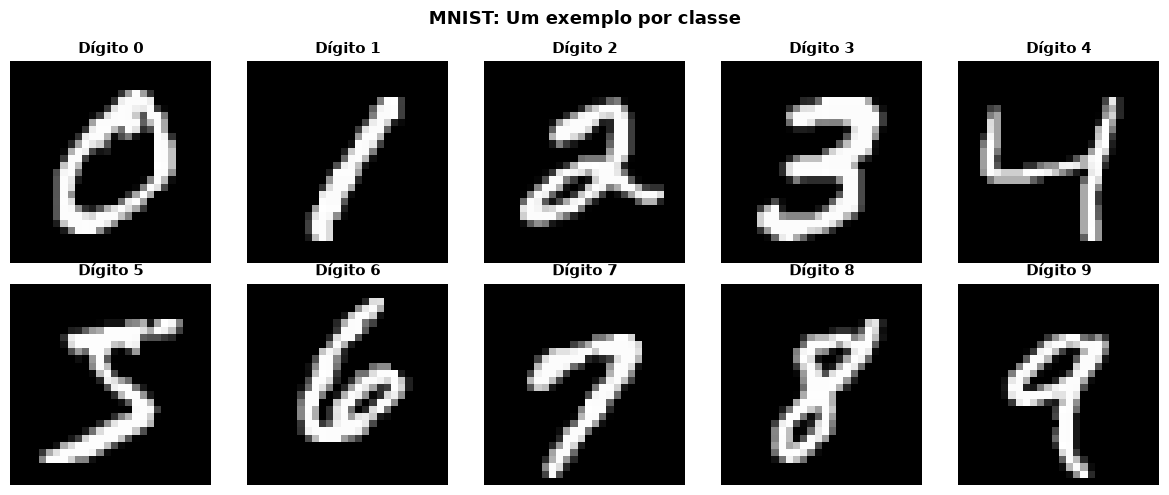

In [ ]:
# Transformação: tensor normalizado com média=0.1307 e desvio=0.3081 (estatísticas do MNIST)
transform_mnist = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

ds_tr = datasets.MNIST("data/mnist", train=True,  download=True, transform=transform_mnist)
ds_te = datasets.MNIST("data/mnist", train=False, download=True, transform=transform_mnist)

loader_tr_m = DataLoader(ds_tr, batch_size=128, shuffle=True,  num_workers=0)
loader_te_m = DataLoader(ds_te, batch_size=256, shuffle=False, num_workers=0)

print(f"Treino : {len(ds_tr):,} imagens  |  Teste: {len(ds_te):,} imagens")
print(f"Shape de uma imagem: {ds_tr[0][0].shape}")   # (1, 28, 28)

# Visualiza 10 exemplos (um por classe)
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
contagem = {}
for img, label in ds_tr:
    if label not in contagem:
        contagem[label] = img
    if len(contagem) == 10:
        break

for ax, (label, img) in zip(axes.ravel(), sorted(contagem.items())):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(f"Dígito {label}", fontsize=11, fontweight="bold")
    ax.axis("off")

plt.suptitle("MNIST: Um exemplo por classe", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### 4.2 O modelo

A mesma arquitetura do notebook 02: dois blocos de convolução seguidos de uma parte densa que classifica. A entrada casa exatamente, porque nossos dígitos fabricados também eram 28×28 em tons de cinza.

| Camada | Saída |
|---|---|
| `Conv2d(1 -> 32, 3×3)` e `ReLU` | 32×26×26 |
| `MaxPool2d(2)` | 32×13×13 |
| `Conv2d(32 -> 64, 3×3)` e `ReLU` | 64×11×11 |
| `MaxPool2d(2)` | 64×5×5 |
| `Flatten` | 1 600 |
| `Linear(1600 -> 128)` e `ReLU` | 128 |
| `Linear(128 -> 10)` | 10 logits |

São cerca de 225 mil parâmetros, e a maior parte deles está na camada `Linear(1600, 128)`, não nas convoluções. Isso é típico: as convoluções fazem o trabalho difícil com poucos pesos, e a parte densa é que engorda a contagem.

In [ ]:
class CNN_MNIST(nn.Module):
    """
    CNN para classificação de dígitos (MNIST).

    Entrada : (batch, 1, 28, 28)
    Saída   : (batch, 10) : logits para cada dígito
    """
    def __init__(self, dropout=0.25):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3),   # → (B, 32, 26, 26)
            nn.ReLU(),
            nn.MaxPool2d(2),                   # → (B, 32, 13, 13)
            nn.Conv2d(32, 64, kernel_size=3),  # → (B, 64, 11, 11)
            nn.ReLU(),
            nn.MaxPool2d(2),                   # → (B, 64, 5, 5)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 5 * 5, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

modelo_mnist = CNN_MNIST().to(device)
total_params = sum(p.numel() for p in modelo_mnist.parameters() if p.requires_grad)
print(f"Parâmetros treináveis: {total_params:,}")
print(modelo_mnist)

Parâmetros treináveis: 225,034
CNN_MNIST(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1600, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)


### 4.3 Treinamento

| Hiperparâmetro | Valor |
|---|---|
| Épocas | 10 |
| Taxa de aprendizado | 0,001 |
| Tamanho do lote | 128 |
| Otimizador | Adam |
| Perda | `CrossEntropyLoss` |
| Dropout | 0,25 |

A diferença em relação ao notebook 02 é que agora avaliamos o conjunto de teste **ao fim de cada época**, e não apenas no final. Assim conseguimos acompanhar as duas curvas lado a lado e perceber overfitting no momento em que ele começa.

Cada linha impressa mostra `Loss: treino/teste` e `Acc: treino/teste`.

In [ ]:
EPOCHS_M = 10
LR_M     = 1e-3

criterio_m   = nn.CrossEntropyLoss()
otimizador_m = optim.Adam(modelo_mnist.parameters(), lr=LR_M)

hist_loss_tr_m, hist_loss_te_m = [], []
hist_acc_tr_m,  hist_acc_te_m  = [], []

for epoca in range(1, EPOCHS_M + 1):
    modelo_mnist.train()
    loss_soma, acertos, total = 0.0, 0, 0
    for xb, yb in loader_tr_m:
        xb, yb = xb.to(device), yb.to(device)
        logits = modelo_mnist(xb)
        loss   = criterio_m(logits, yb)
        otimizador_m.zero_grad()
        loss.backward()
        otimizador_m.step()
        loss_soma += loss.item()
        acertos   += (logits.argmax(1) == yb).sum().item()
        total     += len(yb)

    modelo_mnist.eval()
    loss_te_soma, ac_te, tot_te = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader_te_m:
            xb, yb = xb.to(device), yb.to(device)
            logits = modelo_mnist(xb)
            loss_te_soma += criterio_m(logits, yb).item()
            ac_te        += (logits.argmax(1) == yb).sum().item()
            tot_te       += len(yb)

    hist_loss_tr_m.append(loss_soma / len(loader_tr_m))
    hist_loss_te_m.append(loss_te_soma / len(loader_te_m))
    hist_acc_tr_m.append(acertos / total)
    hist_acc_te_m.append(ac_te / tot_te)

    print(f"Época {epoca:2d} | Loss: {hist_loss_tr_m[-1]:.4f}/{hist_loss_te_m[-1]:.4f} "
          f"| Acc: {acertos/total:.4f}/{ac_te/tot_te:.4f}")

Época  1 | Loss: 0.2092/0.0550 | Acc: 0.9368/0.9815
Época  2 | Loss: 0.0597/0.0309 | Acc: 0.9815/0.9899
Época  3 | Loss: 0.0417/0.0348 | Acc: 0.9873/0.9882
Época  4 | Loss: 0.0336/0.0324 | Acc: 0.9896/0.9892
Época  5 | Loss: 0.0263/0.0297 | Acc: 0.9916/0.9895
Época  6 | Loss: 0.0226/0.0277 | Acc: 0.9928/0.9912
Época  7 | Loss: 0.0191/0.0290 | Acc: 0.9940/0.9910
Época  8 | Loss: 0.0164/0.0237 | Acc: 0.9949/0.9915
Época  9 | Loss: 0.0147/0.0262 | Acc: 0.9949/0.9924
Época 10 | Loss: 0.0133/0.0325 | Acc: 0.9955/0.9904


### 4.4 Resultados

O que observar nos gráficos:

- a perda de treino cai de forma contínua;
- a perda de **teste** cai no começo e depois pode subir um pouco. Quando isso acontece, é o sinal clássico de que a rede começou a decorar, e é o momento em que valeria parar o treino (técnica conhecida como *early stopping*);
- a acurácia de teste estabiliza em torno de **99%**.

Errar 1% em 10 000 imagens são cerca de 100 erros. Olhando esses casos, boa parte são dígitos que uma pessoa também hesitaria em ler.

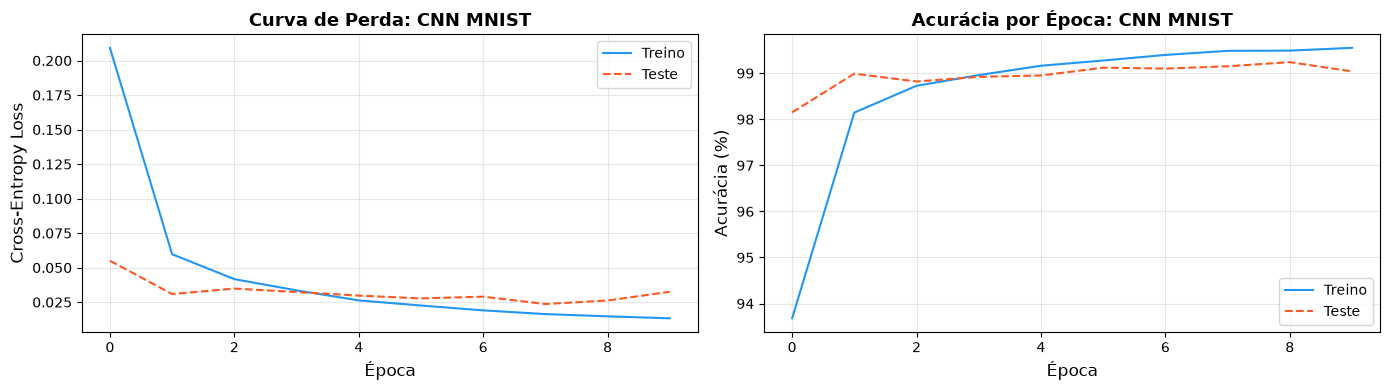


Acurácia final no teste: 99.04%


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

ax = axes[0]
ax.plot(hist_loss_tr_m, label="Treino", color="#2196F3", lw=1.5)
ax.plot(hist_loss_te_m, label="Teste",  color="#FF5722", lw=1.5, linestyle="--")
ax.set_xlabel("Época", fontsize=12); ax.set_ylabel("Cross-Entropy Loss", fontsize=12)
ax.set_title("Curva de Perda: CNN MNIST", fontsize=13, fontweight="bold")
ax.legend(); ax.grid(alpha=0.3)

ax = axes[1]
ax.plot([a*100 for a in hist_acc_tr_m], label="Treino", color="#2196F3", lw=1.5)
ax.plot([a*100 for a in hist_acc_te_m], label="Teste",  color="#FF5722", lw=1.5, linestyle="--")
ax.set_xlabel("Época", fontsize=12); ax.set_ylabel("Acurácia (%)", fontsize=12)
ax.set_title("Acurácia por Época: CNN MNIST", fontsize=13, fontweight="bold")
ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

acc_mnist = hist_acc_te_m[-1]
print(f"\nAcurácia final no teste: {acc_mnist*100:.2f}%")

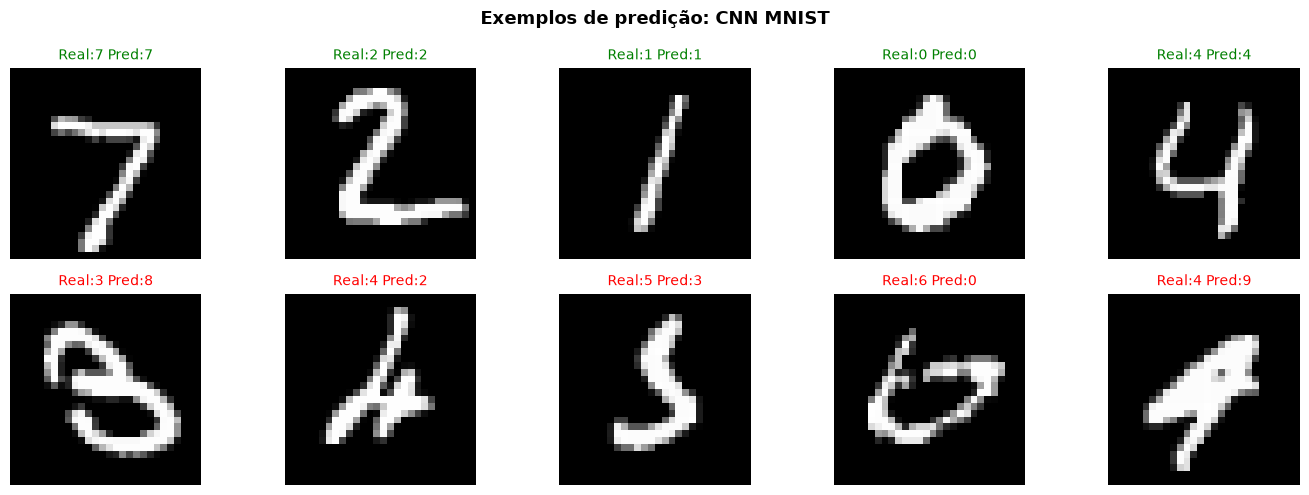

In [ ]:
# Visualiza predições corretas e incorretas
modelo_mnist.eval()
imagens_erros, imagens_certas = [], []

with torch.no_grad():
    for xb, yb in loader_te_m:
        xb, yb = xb.to(device), yb.to(device)
        preds = modelo_mnist(xb).argmax(1)
        for img, real, pred in zip(xb, yb, preds):
            if real != pred and len(imagens_erros) < 5:
                imagens_erros.append((img.cpu(), real.item(), pred.item()))
            if real == pred and len(imagens_certas) < 5:
                imagens_certas.append((img.cpu(), real.item(), pred.item()))
        if len(imagens_erros) == 5 and len(imagens_certas) == 5:
            break

fig, axes = plt.subplots(2, 5, figsize=(14, 5))
for i, (img, real, pred) in enumerate(imagens_certas):
    axes[0, i].imshow(img.squeeze(), cmap="gray")
    axes[0, i].set_title(f"Real:{real} Pred:{pred}", color="green", fontsize=10)
    axes[0, i].axis("off")
for i, (img, real, pred) in enumerate(imagens_erros):
    axes[1, i].imshow(img.squeeze(), cmap="gray")
    axes[1, i].set_title(f"Real:{real} Pred:{pred}", color="red", fontsize=10)
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Corretas", fontsize=11, fontweight="bold", color="green")
axes[1, 0].set_ylabel("Erradas",  fontsize=11, fontweight="bold", color="red")
plt.suptitle("Exemplos de predição: CNN MNIST", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

In [ ]:
import os
os.makedirs("models", exist_ok=True)
torch.save({"model_state_dict": modelo_mnist.state_dict(),
            "accuracy_test":    acc_mnist,
            "n_classes":        10},
           "models/cnn_mnist.pth")

print("Checkpoint salvo em models/cnn_mnist.pth")

Checkpoint salvo em models/cnn_mnist.pth


## 5. Caso 2: CIFAR-10, fotos coloridas de objetos

**Dataset:** [CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html), com 60 000 fotos coloridas de 32×32 pixels, divididas em 10 categorias: `airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck`.

**Tarefa:** dada a foto, dizer qual das 10 categorias aparece nela.

| Característica | MNIST | CIFAR-10 |
|---|---|---|
| Imagens de treino | 60 000 | 50 000 |
| Imagens de teste | 10 000 | 10 000 |
| Resolução | 28×28 | **32×32** |
| Canais | 1 (cinza) | **3 (RGB)** |
| Classes | 10 dígitos | **10 objetos** |
| Dificuldade | baixa | **alta** |

### Por que é tão mais difícil que o MNIST

Um dígito do MNIST é sempre centralizado, branco no fundo preto, e um 7 se parece com qualquer outro 7. Já uma foto de gato pode estar de frente ou de perfil, no sol ou na sombra, grande ou pequena, num sofá ou na grama, e dois gatos podem ser bem diferentes entre si. Some a isso que 32×32 é pouquíssima informação: nessa resolução, até uma pessoa erra bastante.

Por isso vamos acrescentar duas defesas:

**1. Data augmentation.** A cada época, cada imagem de treino é sorteada com pequenas alterações, o que faz a rede ver sempre variações novas:

- `RandomHorizontalFlip()`: espelha a imagem na horizontal. Um carro espelhado continua sendo um carro;
- `RandomCrop(32, padding=4)`: acrescenta uma moldura e recorta 32×32 num lugar aleatório, deslocando de leve o objeto.

Repare que isso é aplicado **apenas no treino**. No teste usamos as imagens originais, porque ali queremos medir desempenho, não gerar variedade.

**2. BatchNorm**, explicado na seção 3, dentro de cada bloco convolucional.

### 5.1 Carregando e visualizando

In [ ]:
CLASSES_CIFAR = ["airplane","automobile","bird","cat","deer",
                 "dog","frog","horse","ship","truck"]

# Data augmentation no treino; apenas normalização no teste
transform_tr_c = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),   # média por canal RGB
                         (0.2023, 0.1994, 0.2010)),
])
transform_te_c = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),
                         (0.2023, 0.1994, 0.2010)),
])

ds_tr_c = datasets.CIFAR10("data/cifar10", train=True,  download=True, transform=transform_tr_c)
ds_te_c = datasets.CIFAR10("data/cifar10", train=False, download=True, transform=transform_te_c)

loader_tr_c = DataLoader(ds_tr_c, batch_size=128, shuffle=True,  num_workers=0)
loader_te_c = DataLoader(ds_te_c, batch_size=256, shuffle=False, num_workers=0)

print(f"Treino : {len(ds_tr_c):,} imagens  |  Teste: {len(ds_te_c):,} imagens")
print(f"Shape de uma imagem: {ds_tr_c[0][0].shape}")   # (3, 32, 32)

# Visualiza exemplos por classe
fig, axes = plt.subplots(2, 5, figsize=(14, 5))
contagem_c = {}
# Usa dataset sem augmentation para visualização mais limpa
ds_vis = datasets.CIFAR10("data/cifar10", train=True, download=False,
                           transform=transforms.ToTensor())
for img, label in ds_vis:
    if label not in contagem_c:
        contagem_c[label] = img
    if len(contagem_c) == 10:
        break

for ax, (label, img) in zip(axes.ravel(), sorted(contagem_c.items())):
    ax.imshow(img.permute(1, 2, 0).numpy())   # (C,H,W) → (H,W,C)
    ax.set_title(CLASSES_CIFAR[label], fontsize=10, fontweight="bold")
    ax.axis("off")

plt.suptitle("CIFAR-10: Um exemplo por classe", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

36.8%

### 5.2 O modelo, agora com BatchNorm

Rede mais profunda: **três** blocos convolucionais, cada um com convolução, BatchNorm, ReLU e pooling.

| Bloco | Operações | Saída |
|---|---|---|
| Bloco 1 | `Conv2d(3 -> 32, 3, padding=1)`, BN, ReLU, MaxPool | 32×16×16 |
| Bloco 2 | `Conv2d(32 -> 64, 3, padding=1)`, BN, ReLU, MaxPool | 64×8×8 |
| Bloco 3 | `Conv2d(64 -> 128, 3, padding=1)`, BN, ReLU, MaxPool | 128×4×4 |
| Cabeça | `Flatten` (2 048), `Linear(2048 -> 512)`, `Dropout`, `Linear(512 -> 10)` | 10 logits |

Três detalhes para observar:

**O primeiro número muda de 1 para 3.** É o `Conv2d(3, ...)`: a imagem tem três canais de cor, então cada filtro agora é um bloquinho 3×3×3 que olha vermelho, verde e azul ao mesmo tempo.

**A quantidade de filtros cresce a cada bloco** (32, 64, 128) enquanto o tamanho da imagem encolhe (16, 8, 4). Esse padrão é padrão em CNNs: conforme a rede perde resolução espacial, ela ganha variedade de padrões detectados.

**O total salta para cerca de 1,1 milhão de parâmetros**, quase cinco vezes a rede do MNIST. Problema mais difícil, modelo maior.

In [ ]:
class CNN_CIFAR10(nn.Module):
    """
    CNN com BatchNorm para classificação CIFAR-10.

    Entrada : (batch, 3, 32, 32)
    Saída   : (batch, 10) : logits para cada classe
    """
    def __init__(self, dropout=0.3):
        super().__init__()
        self.features = nn.Sequential(
            # Bloco 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),   # → (B, 32, 32, 32)
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),                               # → (B, 32, 16, 16)
            # Bloco 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),  # → (B, 64, 16, 16)
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),                               # → (B, 64, 8, 8)
            # Bloco 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1), # → (B, 128, 8, 8)
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),                               # → (B, 128, 4, 4)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),                       # → 128 * 4 * 4 = 2048
            nn.Linear(128 * 4 * 4, 512),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(512, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

modelo_cifar = CNN_CIFAR10().to(device)
total_cifar  = sum(p.numel() for p in modelo_cifar.parameters() if p.requires_grad)
print(f"Parâmetros treináveis: {total_cifar:,}")
print(modelo_cifar)

Parâmetros treináveis: 1,147,914
CNN_CIFAR10(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=512, bias=Tr

### 5.3 Treinamento

| Hiperparâmetro | Valor | Observação |
|---|---|---|
| Épocas | 5 | valor baixo de propósito, para a aula caber no tempo |
| Taxa de aprendizado | 0,001 | com um agendador que a reduz ao longo do treino |
| Tamanho do lote | 128 | |
| Otimizador | Adam | |
| Perda | `CrossEntropyLoss` | |
| Dropout | 0,3 | um pouco maior que no MNIST |
| BatchNorm | sim | estabiliza o treino |
| Data augmentation | flip e crop | só no treino |

**Sobre o agendador de taxa de aprendizado.** O `StepLR(step_size=10, gamma=0.5)` corta a taxa de aprendizado pela metade a cada 10 épocas. A ideia é dar passos largos no começo, quando estamos longe do mínimo, e passos curtos no fim, para não ficar pulando em volta do fundo do vale. Como aqui rodamos apenas 5 épocas, ele ainda não chega a agir: está no código para você ver como se usa e poder aproveitá-lo ao aumentar `EPOCHS_C`.

> **Atenção ao tempo:** em CPU, cada época do CIFAR-10 leva alguns minutos. Se quiser subir para 20 ou 30 épocas, e chegar a uma acurácia bem melhor, vale rodar numa máquina com GPU.

In [ ]:
EPOCHS_C = 30
LR_C     = 1e-3

criterio_c   = nn.CrossEntropyLoss()
otimizador_c = optim.Adam(modelo_cifar.parameters(), lr=LR_C)
scheduler    = optim.lr_scheduler.StepLR(otimizador_c, step_size=10, gamma=0.5)

hist_loss_tr_c2, hist_loss_te_c2 = [], []
hist_acc_tr_c2,  hist_acc_te_c2  = [], []

for epoca in range(1, EPOCHS_C + 1):
    modelo_cifar.train()
    loss_soma, acertos, total = 0.0, 0, 0
    for xb, yb in loader_tr_c:
        xb, yb = xb.to(device), yb.to(device)
        logits = modelo_cifar(xb)
        loss   = criterio_c(logits, yb)
        otimizador_c.zero_grad()
        loss.backward()
        otimizador_c.step()
        loss_soma += loss.item()
        acertos   += (logits.argmax(1) == yb).sum().item()
        total     += len(yb)

    modelo_cifar.eval()
    loss_te_soma, ac_te, tot_te = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader_te_c:
            xb, yb = xb.to(device), yb.to(device)
            logits = modelo_cifar(xb)
            loss_te_soma += criterio_c(logits, yb).item()
            ac_te        += (logits.argmax(1) == yb).sum().item()
            tot_te       += len(yb)

    scheduler.step()

    hist_loss_tr_c2.append(loss_soma / len(loader_tr_c))
    hist_loss_te_c2.append(loss_te_soma / len(loader_te_c))
    hist_acc_tr_c2.append(acertos / total)
    hist_acc_te_c2.append(ac_te / tot_te)

    if epoca % 1 == 0:
        lr_atual = scheduler.get_last_lr()[0]
        print(f"Época {epoca:2d} | Loss: {hist_loss_tr_c2[-1]:.4f}/{hist_loss_te_c2[-1]:.4f} "
              f"| Acc: {acertos/total:.4f}/{ac_te/tot_te:.4f} | lr={lr_atual:.5f}")

Época  1 | Loss: 1.0504/0.9310 | Acc: 0.6249/0.6787 | lr=0.00100
Época  2 | Loss: 0.9383/0.8016 | Acc: 0.6672/0.7195 | lr=0.00100
Época  3 | Loss: 0.8826/0.8693 | Acc: 0.6873/0.6957 | lr=0.00100
Época  4 | Loss: 0.8364/0.7571 | Acc: 0.7071/0.7301 | lr=0.00100
Época  5 | Loss: 0.7880/0.7111 | Acc: 0.7213/0.7468 | lr=0.00100


### 5.4 Resultados

Com 5 épocas a acurácia de teste fica em torno de **75%**. Parece pouco depois dos 99% do MNIST, mas coloque em perspectiva: chutar entre 10 classes daria 10%.

Observe também que as curvas de treino e de teste ficam **próximas**, e que a acurácia de teste às vezes supera a de treino. Isso não é um erro: o data augmentation deixa as imagens de treino mais difíceis que as de teste, e o dropout atrapalha o treino de propósito, mas fica desligado na avaliação.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

ax = axes[0]
ax.plot(hist_loss_tr_c2, label="Treino", color="#2196F3", lw=1.5)
ax.plot(hist_loss_te_c2, label="Teste",  color="#FF5722", lw=1.5, linestyle="--")
ax.set_xlabel("Época", fontsize=12); ax.set_ylabel("Cross-Entropy Loss", fontsize=12)
ax.set_title("Curva de Perda: CNN CIFAR-10", fontsize=13, fontweight="bold")
ax.legend(); ax.grid(alpha=0.3)

ax = axes[1]
ax.plot([a*100 for a in hist_acc_tr_c2], label="Treino", color="#2196F3", lw=1.5)
ax.plot([a*100 for a in hist_acc_te_c2], label="Teste",  color="#FF5722", lw=1.5, linestyle="--")
ax.set_xlabel("Época", fontsize=12); ax.set_ylabel("Acurácia (%)", fontsize=12)
ax.set_title("Acurácia por Época: CNN CIFAR-10", fontsize=13, fontweight="bold")
ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

acc_cifar = hist_acc_te_c2[-1]
print(f"\nAcurácia final no teste: {acc_cifar*100:.2f}%")

### 5.5 Matriz de confusão: descobrindo onde o modelo se confunde

A acurácia geral diz o quanto o modelo acerta, mas não **onde** ele erra. A matriz de confusão responde isso. É uma tabela em que:

- cada **linha** é a classe verdadeira da imagem;
- cada **coluna** é a classe que o modelo respondeu;
- cada **número** é a quantidade de imagens naquela combinação.

Logo, a **diagonal principal** (linha igual à coluna) são os acertos, e tudo fora dela são erros. Quanto mais concentrada na diagonal, melhor o modelo.

O valor está nos erros fora da diagonal, porque eles têm padrão. No CIFAR-10 é normal encontrar muitas trocas entre `cat` e `dog`, ou entre `automobile` e `truck`: são classes parecidas em forma, textura e contexto. Já confundir `airplane` com `frog` seria estranho e sugeriria um problema mais sério, em vez de uma dificuldade natural da tarefa.

In [ ]:
# Matriz de confusão CIFAR-10
modelo_cifar.eval()
todos_reais, todos_preds = [], []

with torch.no_grad():
    for xb, yb in loader_te_c:
        xb = xb.to(device)
        preds = modelo_cifar(xb).argmax(1).cpu()
        todos_reais.extend(yb.numpy())
        todos_preds.extend(preds.numpy())

todos_reais  = np.array(todos_reais)
todos_preds  = np.array(todos_preds)

matriz = np.zeros((10, 10), dtype=int)
for r, p in zip(todos_reais, todos_preds):
    matriz[r, p] += 1

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(matriz, cmap="Blues")
plt.colorbar(im, ax=ax)
ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES_CIFAR, rotation=35, ha="right", fontsize=9)
ax.set_yticks(range(10)); ax.set_yticklabels(CLASSES_CIFAR, fontsize=9)
ax.set_xlabel("Predito", fontsize=12); ax.set_ylabel("Real", fontsize=12)
ax.set_title("Matriz de Confusão: CNN CIFAR-10", fontsize=13, fontweight="bold")
for i in range(10):
    for j in range(10):
        ax.text(j, i, str(matriz[i, j]), ha="center", va="center", fontsize=7,
                color="white" if matriz[i, j] > matriz.max() * 0.6 else "black")
plt.tight_layout()
plt.show()

# Acurácia por classe
print("\nAcurácia por classe:")
for i, nome in enumerate(CLASSES_CIFAR):
    ac = matriz[i, i] / matriz[i].sum()
    print(f"  {nome:12s}: {ac*100:.1f}%")

In [ ]:
torch.save({"model_state_dict": modelo_cifar.state_dict(),
            "accuracy_test":    acc_cifar,
            "classes":          CLASSES_CIFAR,
            "n_classes":        10},
           "models/cnn_cifar10.pth")
print("Checkpoint salvo em models/cnn_cifar10.pth")

## 6. Conclusão da aula

### O caminho que percorremos

| Notebook | O que construímos | Resultado |
|---|---|---|
| **00** | um neurônio treinado por gradiente descendente, escrito na mão | descobriu sozinho a regra da temperatura |
| **01** | uma CNN completa em NumPy, com 20 parâmetros | 98% em O contra X |
| **02** | a mesma CNN em PyTorch, num dataset fabricado por nós | 94% em 10 dígitos |
| **03** | CNNs em datasets reais | 99% no MNIST, cerca de 75% no CIFAR-10 |

### As lições dos dois casos deste notebook

**MNIST é fácil, e isso também é informação.** Com dois blocos convolucionais e 10 épocas chegamos a 99%. Dígitos escritos à mão são centralizados, em tons de cinza e com fundo limpo, ou seja, quase toda a variação está na forma, que é exatamente o que uma CNN detecta bem.

**CIFAR-10 é difícil.** Mesmo com uma rede cinco vezes maior, BatchNorm, dropout e data augmentation, ficamos perto de 75% em 5 épocas. Treinando por 30 épocas, essa mesma rede costuma chegar a algo entre 80% e 85%, e arquiteturas modernas passam de 95%.

**A mesma receita serviu para tudo.** Convolução para achar padrões locais, ReLU para introduzir não linearidade, pooling para resumir, camada densa para decidir, entropia cruzada para medir o erro e gradiente descendente para corrigir os pesos. Do neurônio do notebook 00 até o 1,1 milhão de parâmetros daqui, o que mudou foi a escala, não o mecanismo.

### Para onde seguir depois da aula

| Assunto | O que é | Por que importa |
|---|---|---|
| **Transfer learning** | pegar uma rede já treinada em milhões de imagens e adaptá-la ao seu problema | é o que se faz na prática quando há poucos dados, e quase sempre supera treinar do zero |
| **Arquiteturas modernas** | ResNet, EfficientNet, ConvNeXt | resolvem o problema de treinar redes muito profundas |
| **Aumento de dados avançado** | rotação, recorte, mistura de imagens | mais generalização sem precisar coletar dados novos |
| **Vision Transformers** | a alternativa atual às CNNs para imagens | dominam os rankings em datasets grandes |

### Para praticar

1. Aumente `EPOCHS_C` de `5` para `20` e veja até onde a acurácia do CIFAR-10 chega.
2. Tire o `BatchNorm2d` da rede do CIFAR-10 e compare a velocidade de convergência.
3. Desligue o data augmentation (use `transform_te_c` também no treino) e observe a distância entre as curvas de treino e de teste aumentar.
4. Leia a matriz de confusão e liste os três pares de classes que o modelo mais troca. Faz sentido para os seus olhos?

---

Fim da aula. Os quatro notebooks, do neurônio único até o CIFAR-10, cobrem o mesmo ciclo: **prever, medir o erro, calcular a inclinação e dar um passo contra ela.**